# DA3 project November 2026

Supervisor: Nicolas Catz

Authors: Benjamin Mellet, Eliana Charah, Lena Mollon, Arthur Lesle, Zoe Andreo

### Loading libraries and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter
from scipy.io import loadmat
from pathlib import Path
from matplotlib.patches import Rectangle
import re
import os


if os.getcwd().endswith('scripts'):
    os.chdir('..')
os.getcwd()

'/Users/arthur/git/Master amu/DA3/DA3_VSDI_S1_G1_2026'

In [2]:
current_dir = Path.cwd()
folder = current_dir.parent
data_folder = folder / 'data'

## 1. Data pre-processing

In [4]:
## load the condition
## condition is the order of the finger stimulations

condition_load = np.load(data_folder / 'New_list_conditions.npy')
condition = []

for i in condition_load[0::2]:
    cond = re.split('_', str(i))[0]
    condition.append(cond[-1])

condition = np.array(condition)

In [6]:
## extract data from trials
sig = 1

Cortex = np.load(data_folder / 'Image_Cortex.npy')  
x = np.arange(1, 31, 1)

delta_f = []

for trial_num in x:
    stim = np.load(data_folder / f'Trial_{trial_num}_Stim.npy')
    control = np.load(data_folder / f'Trial_{trial_num}_Control.npy')

    df = (stim - control)/control
    delta_f.append(df)

delta_f = np.array(delta_f)

df_filtered = gaussian_filter(delta_f.copy(), sigma=(0, sig, sig, 0)) 

In [7]:
cond1_index = np.where(condition == '1')[0]
cond2_index = np.where(condition == '2')[0]
cond3_index = np.where(condition == '3')[0]

In [8]:
## filter before or after taking mean?

cond1_ave = np.mean(df_filtered[cond1_index], axis=0)
cond2_ave = np.mean(df_filtered[cond2_index], axis=0)
cond3_ave = np.mean(df_filtered[cond3_index], axis=0)

## 2. Threhsolding based on maximum relative fluorescent activity (DF/F) 

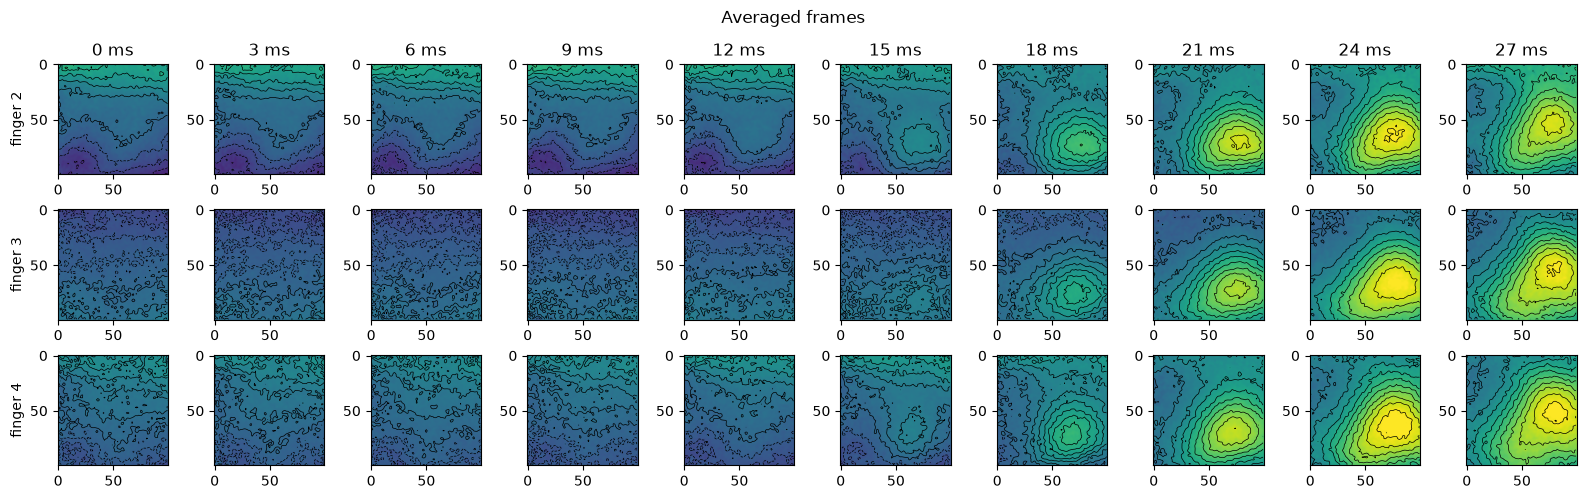

In [12]:
fig, ax = plt.subplots(3, 10, figsize=(16,5))

vmin = np.min(cond1_ave)
vmax=np.max(cond1_ave)

level=10

for i in range(10):
    ax[0][i].imshow(cond1_ave[:,:,33+i], vmin=vmin, vmax=vmax)
    ax[1][i].imshow(cond2_ave[:,:,33+i], vmin=vmin, vmax=vmax)
    ax[2][i].imshow(cond3_ave[:,:,33+i], vmin=vmin, vmax=vmax)

    ax[0][i].contour(cond1_ave[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[1][i].contour(cond2_ave[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[2][i].contour(cond3_ave[:,:,33+i], levels=level, linewidths=0.5, colors='k')

    ax[0][i].set_title(f'{i*3} ms')

ax[0][0].set_ylabel('finger 2')
ax[1][0].set_ylabel('finger 3')
ax[2][0].set_ylabel('finger 4')

fig.suptitle('Averaged frames')
plt.tight_layout()

In [13]:
cond1_max = cond1_ave[:,:,33:40].max()
cond2_max = cond2_ave[:,:,33:40].max()
cond3_max = cond3_ave[:,:,33:40].max()

In [14]:
thresh = 0.85

cond1_thresh = np.where(cond1_ave > cond1_max * thresh, cond1_ave, 0)
cond2_thresh = np.where(cond2_ave > cond2_max * thresh, cond1_ave, 0)
cond3_thresh = np.where(cond3_ave > cond3_max * thresh, cond1_ave, 0)

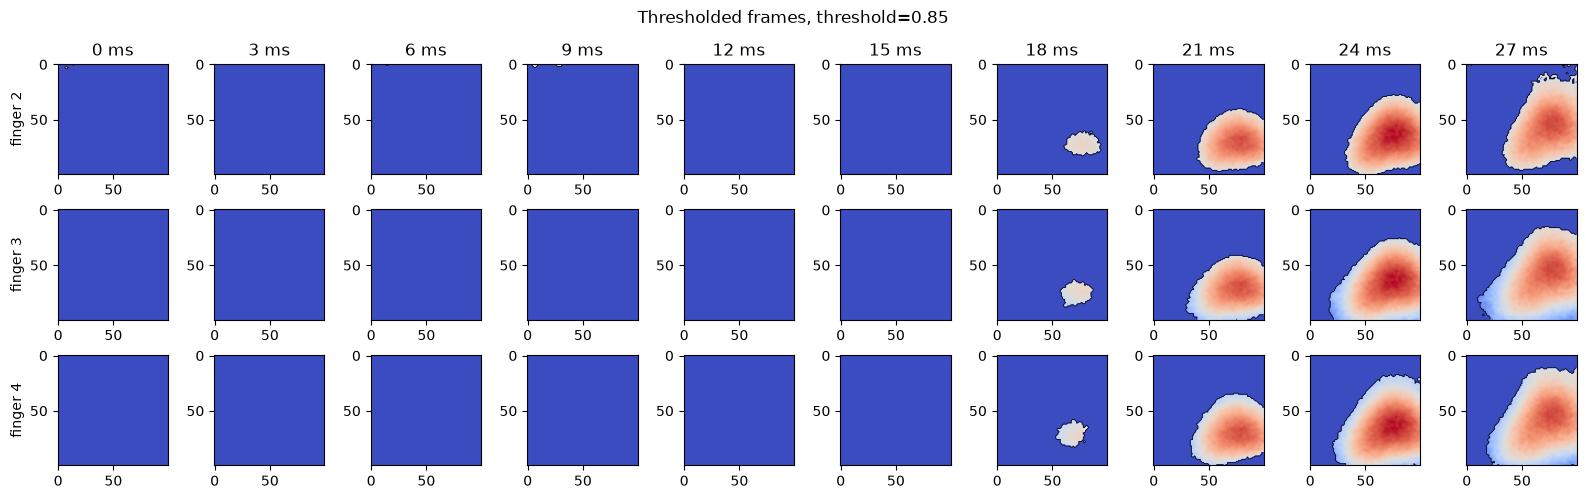

In [17]:
fig, ax = plt.subplots(3, 10, figsize=(16,5))

vmin = np.min(cond1_thresh)
vmax=np.max(cond1_thresh)

level=0

for i in range(10):
    ax[0][i].imshow(cond1_thresh[:,:,33+i], vmin=vmin, vmax=vmax, cmap='coolwarm')
    ax[1][i].imshow(cond2_thresh[:,:,33+i], vmin=vmin, vmax=vmax, cmap='coolwarm')
    ax[2][i].imshow(cond3_thresh[:,:,33+i], vmin=vmin, vmax=vmax, cmap='coolwarm')

    ax[0][i].contour(cond1_thresh[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[1][i].contour(cond2_thresh[:,:,33+i], levels=level, linewidths=0.5, colors='k')
    ax[2][i].contour(cond3_thresh[:,:,33+i], levels=level, linewidths=0.5, colors='k')

    ax[0][i].set_title(f'{i*3} ms')

ax[0][0].set_ylabel('finger 2')
ax[1][0].set_ylabel('finger 3')
ax[2][0].set_ylabel('finger 4')

fig.suptitle(f'Thresholded frames, threshold={thresh}')
plt.tight_layout()

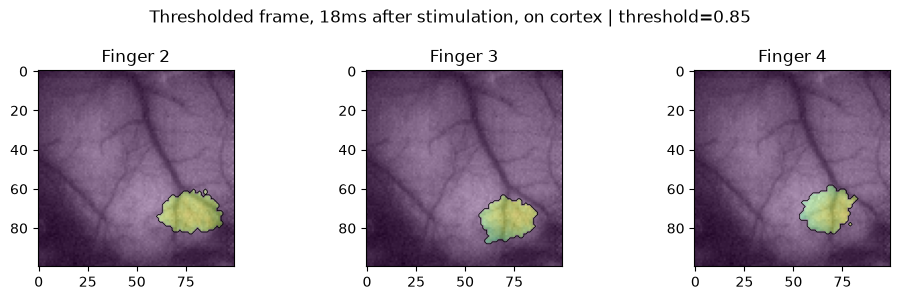

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3))
frame = 39 # ie., 18ms after stimulation

ax[0].imshow(Cortex, alpha=0.6)
ax[1].imshow(Cortex, alpha=0.6)
ax[2].imshow(Cortex, alpha=0.6)

ax[0].imshow(cond1_thresh[:,:,frame])
ax[1].imshow(cond2_thresh[:,:,frame])
ax[2].imshow(cond3_thresh[:,:,frame])

ax[0].contour(cond1_thresh[:,:,frame], levels=0, linewidths=0.5, colors='k')
ax[1].contour(cond2_thresh[:,:,frame], levels=0, linewidths=0.5, colors='k')
ax[2].contour(cond3_thresh[:,:,frame], levels=0, linewidths=0.5, colors='k')

ax[0].set_title('Finger 2')
ax[1].set_title('Finger 3')
ax[2].set_title('Finger 4')

fig.suptitle(f'Thresholded frame, {(frame-33)*3}ms after stimulation, on cortex | threshold={thresh}')
plt.tight_layout()

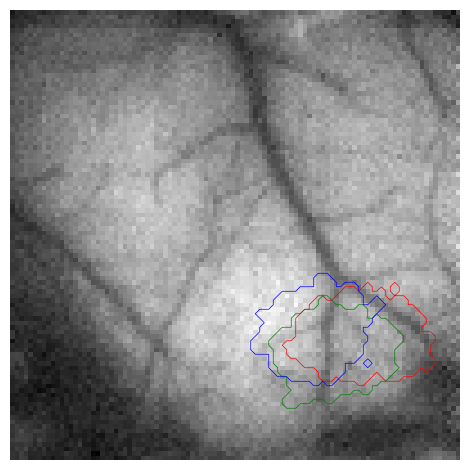

In [36]:
plt.imshow(Cortex)
cs1 = plt.contour(cond1_thresh[:,:,frame], levels=0, linewidths=0.5, colors='r')
cs2 = plt.contour(cond2_thresh[:,:,frame], levels=0, linewidths=0.5, colors='g')
cs3 = plt.contour(cond3_thresh[:,:,frame], levels=0, linewidths=0.5, colors='b')

plt.axis('off')
plt.tight_layout()

- The red contour represent finger 2
- The green contour represents finger 3
- The blue contour represents finger 4

### 2.1 Testing different methods to extract the somatopy from maximum thresholding

#### *2.1.1.* 1st method: Competition

As can be seen in the figure above, each finger occupies a region. However, these regions are highly overlapped. Therefore, our first instinct was to use apply a competition approach. That is, for each pixel in one region that overlaps a pixel from the other regions, the pixel that has the highest fluorescence 'wins' that pixel. Pixels were each region has the same fluorescence are considered as a tie and are not assigned to any particular region.

In [37]:
roi1 = cond1_thresh[40:,40:,39]
roi2 = cond2_thresh[40:,40:,39]
roi3 = cond3_thresh[40:,40:,39]

In [38]:
pixel_overlap = []
for i in range(60):
    row = []
    for j in range(60):
        if roi1[i][j] != 0 and roi2[i][j] != 0 and roi3[i][j] != 0:
            if roi1[i][j] > roi2[i][j] and roi1[i][j] > roi3[i][j]:
                row.append(1)
            elif roi2[i][j] > roi1[i][j] and roi2[i][j] > roi3[i][j]:
                row.append(2)
            elif roi3[i][j] > roi2[i][j] and roi3[i][j] > roi1[i][j]:
                row.append(3)
            else:
                row.append(4)
        else:
            row.append(0)
    pixel_overlap.append(row)

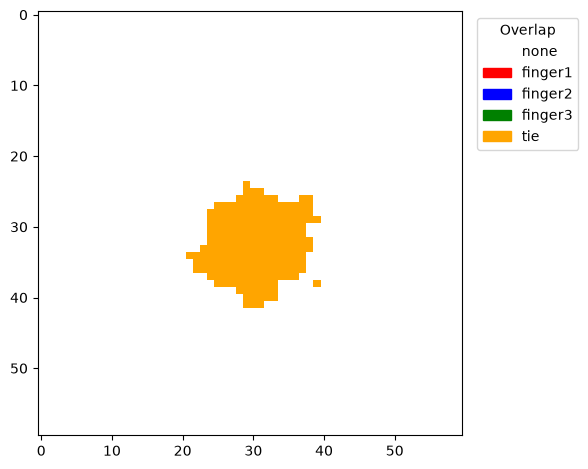

In [39]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

colors = ['white', 'red', 'blue', 'green', 'orange']
labels = ['none', 'finger1', 'finger2', 'finger3', 'tie']

cmap = ListedColormap(colors)

fig, ax = plt.subplots()
ax.imshow(np.array(pixel_overlap), cmap=cmap, vmin=0, vmax=4, interpolation='nearest')

handles = [mpatches.Patch(color=c, label=l) for c, l in zip(colors, labels)]
ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', title='Overlap')

plt.tight_layout()
plt.show()

#### 2.1.2. 2nd method: Contrasts

Seeing that the competition method did not work, we then tested a contrast method inspired from fMRI data analysis. The idea was to substract the mean relative fluorescent change (DF/F) of two fingers from the remaining finger. In doing so we hope to isolate the region of activity preferrentially activated by that finer

In [21]:
d1_contrast = roi1 - np.mean([roi2, roi3], axis=0)
d2_contrast = roi2 - np.mean([roi1, roi3], axis=0)
d3_contrast = roi3 - np.mean([roi1, roi2], axis=0)

In [22]:
threshold=0.0
d1_contrast[d1_contrast < threshold] = 0
d2_contrast[d2_contrast < threshold] = 0
d3_contrast[d3_contrast < threshold] = 0

Text(0.5, 1.0, 'Finger 3 - mean(finger1 + finger2)')

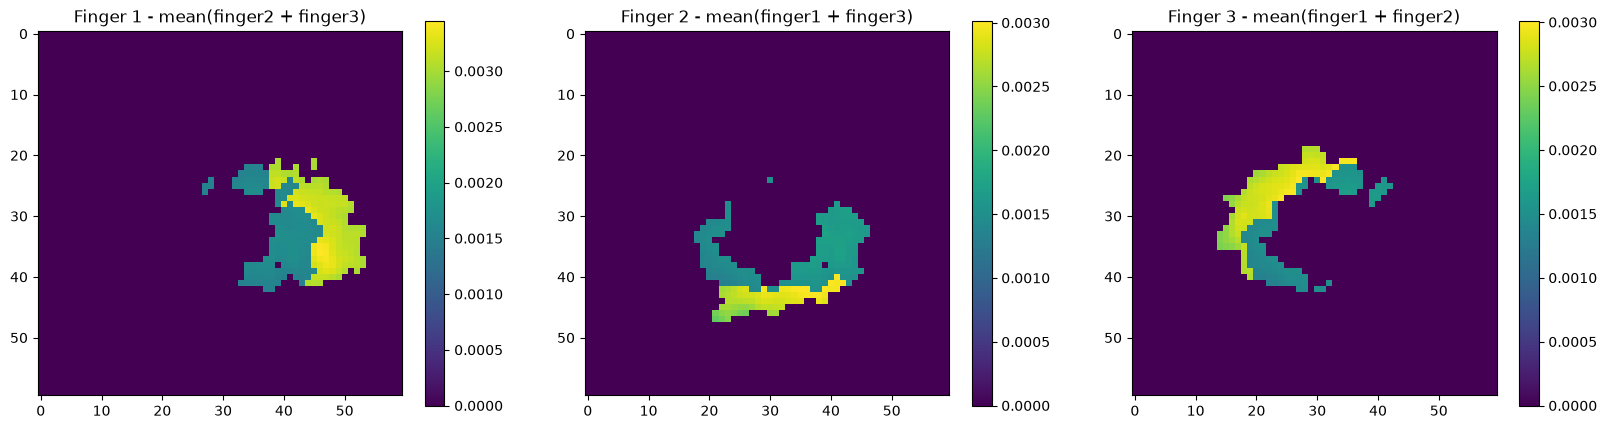

In [46]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))

im1 = ax1.imshow(d1_contrast)
im2 = ax2.imshow(d2_contrast)
im3 = ax3.imshow(d3_contrast)

fig.colorbar(im2, ax=ax2)
fig.colorbar(im1, ax=ax1)
fig.colorbar(im3, ax=ax3)

ax1.set_title('Finger 1 - mean(finger2 + finger3)')
ax2.set_title('Finger 2 - mean(finger1 + finger3)')
ax3.set_title('Finger 3 - mean(finger1 + finger2)')


As we can see, this method was not successful. The regions that were preferrentially activated were extremes of the bondaries which makes sense as these are the regions with little overlap.

#### 3rd method: Finding the center

The third idea was to extract the center of the extracted boundaries for each finger.

In [40]:
from cv2 import moments

center1 = None
center2 = None
center3 = None

M1 = moments(cond1_thresh[:,:,39])
M2 = moments(cond2_thresh[:,:,39])
M3 = moments(cond3_thresh[:,:,39])

center1 = (int(M1["m10"] / M1["m00"]), int(M1["m01"] / M1["m00"]))
center2 = (int(M2["m10"] / M2["m00"]), int(M2["m01"] / M2["m00"]))
center3 = (int(M3["m10"] / M3["m00"]), int(M3["m01"] / M3["m00"]))

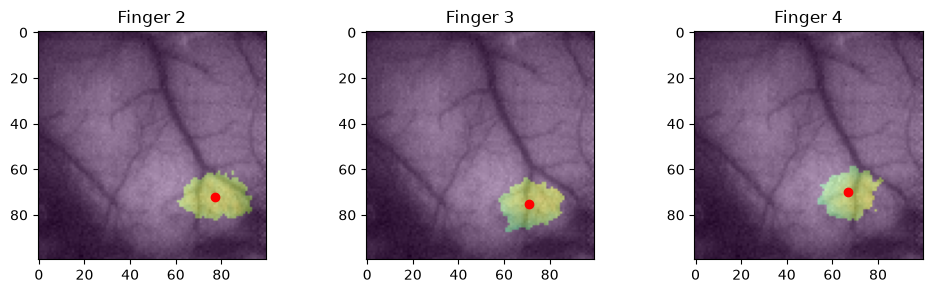

In [42]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3))

ax[0].imshow(cond1_thresh[:,:,39])
ax[1].imshow(cond2_thresh[:,:,39])
ax[2].imshow(cond3_thresh[:,:,39])

ax[0].imshow(Cortex, alpha=0.6)
ax[1].imshow(Cortex, alpha=0.6)
ax[2].imshow(Cortex, alpha=0.6)

ax[0].plot(center1[0], center1[1], 'ro')
ax[1].plot(center2[0], center2[1], 'ro')
ax[2].plot(center3[0], center3[1], 'ro')

ax[0].set_title('Finger 2')
ax[1].set_title('Finger 3')
ax[2].set_title('Finger 4')

plt.tight_layout()

This method seemed the most promising for extracting an accurate somatotopy.

Below is the overlayed center for each finger on the same cortex image.

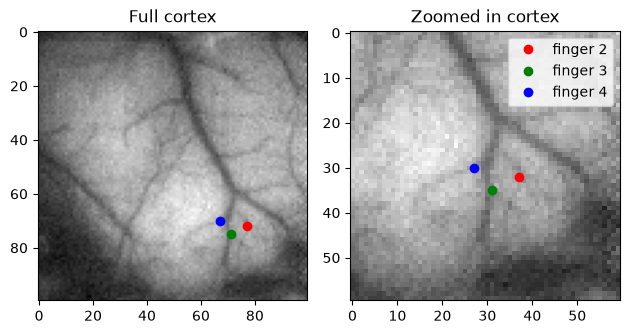

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.imshow(Cortex)
ax1.plot(center1[0], center1[1], 'ro', label='finger2')
ax1.plot(center2[0], center2[1], 'go', label='finger3')
ax1.plot(center3[0], center3[1], 'bo', label='finger4')

ax2.imshow(Cortex[40:, 40:])
ax2.plot(center1[0]-40, center1[1]-40, 'ro', label='finger 2')
ax2.plot(center2[0]-40, center2[1]-40, 'go', label='finger 3')
ax2.plot(center3[0]-40, center3[1]-40, 'bo', label='finger 4')

ax1.set_title('Full cortex')
ax2.set_title('Zoomed in cortex')

plt.legend()
plt.tight_layout()

## 3. Latency extraction

The same preprocessing steps were applied and used in this section

In [51]:
# Extracting the baseline (0 - 100ms, ie. pre-stim activity)

baseline1 = np.mean(cond1_ave[:,:,:33], axis=2)
baseline2 = np.mean(cond2_ave[:,:,:33], axis=2)
baseline3 = np.mean(cond3_ave[:,:,:33], axis=2)

### 3.1. One sample t-test

Here we want to carry out a one sample t-test between each pixel post-stimulus with the pre-stimulus baseline to find the first instance at which we get significative relative fluorescence above the baseline.

In [53]:
from scipy.stats import ttest_ind

def calc_ttest(data, start, end, alpha=0.01):
    lat = np.zeros(shape=(100,100))
    for k in range(end):
        for i in range(100):
            for j in range(100):
                _, pvalue = ttest_ind(data[i,j,:33], data[i,j,start+k], axis=0, alternative='less')
                if pvalue < alpha:
                    if lat[i,j] == 0:
                        lat[i,j] = start+k
    return lat

We started to start at frame 37 (i.e. 12ms after the stimulation) because we saw in our own analysis and from the literature we know we should not have a response within the first 12ms.

In [56]:
lat1 = calc_ttest(cond1_ave, start=37, end=10, alpha=0.01)
lat2 = calc_ttest(cond2_ave, start=37, end=10, alpha=0.01)
lat3 = calc_ttest(cond3_ave, start=37, end=10, alpha=0.01)

In [57]:
# function to convert the frames into ms

def frames_ms(frames):
    ms = np.where(frames>0, (frames-33)*3, 0)
    return ms

In [59]:
# latencies in ms and not in frames

lat1_ms = frames_ms(lat1)
lat2_ms = frames_ms(lat2)
lat3_ms = frames_ms(lat3)

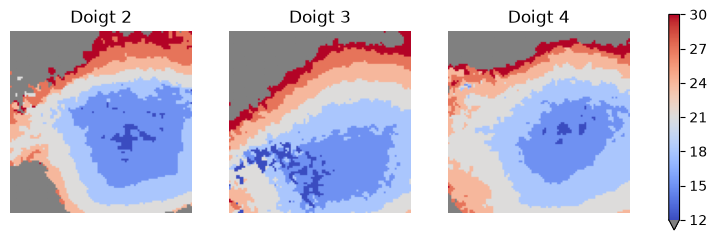

In [61]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10, 7))

cmap = plt.colormaps['coolwarm'].copy()
cmap.set_under('grey')
cmap.set_over('grey')

im1 = ax1.imshow(lat1_ms, cmap=cmap, vmin=12, vmax=30)
im2 = ax2.imshow(lat2_ms, cmap=cmap, vmin=12, vmax=30)
im3 = ax3.imshow(lat3_ms, cmap=cmap, vmin=12, vmax=30)

ax1.set_axis_off()
ax2.set_axis_off()
ax3.set_axis_off()

ax1.set_title('Doigt 2')
ax2.set_title('Doigt 3')
ax3.set_title('Doigt 4')

fig.colorbar(im3, ax=[ax1, ax2, ax3], shrink=0.4, extend='min', ticks=np.unique(lat1_ms[lat1_ms>0]))

### 3.2 Extract the latency

In [63]:
def extract_latency(data, baseline, first_lat):
    # data: (100, 100, 255), baseline and first_lat: (100, 100)
    x2 = first_lat.astype(int)
    x1 = np.where(x2 > 0, x2 - 1, x2)

    # pick the frame at x2 and x1 for every pixel
    y2 = np.take_along_axis(data, x2[..., None], axis=2)[..., 0]
    y1 = np.take_along_axis(data, x1[..., None], axis=2)[..., 0]

    m = (y2 - y1) / (x2 - x1)
    c = y1 - m * x1
    latency = (baseline - c) / m

    return frames_ms(latency)

In [64]:
cond1_lat = extract_latency(cond1_ave, baseline1, lat1)
cond2_lat = extract_latency(cond2_ave, baseline2, lat2)
cond3_lat = extract_latency(cond3_ave, baseline3, lat3)

/var/folders/hj/zrv88xk141b_66z8wmnrg1d80000gp/T/ipykernel_68926/1051607618.py:10: RuntimeWarning: invalid value encountered in divide
  m = (y2 - y1) / (x2 - x1)


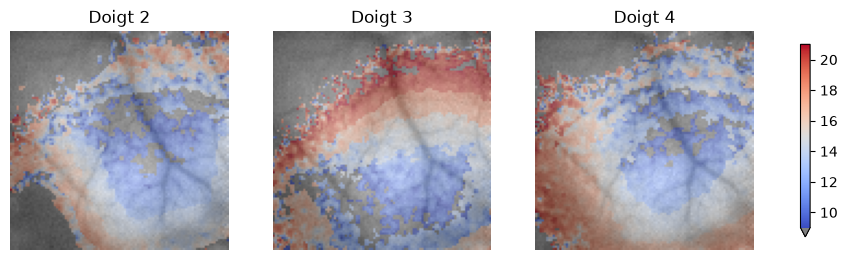

In [65]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 5))

cmap = plt.colormaps['coolwarm'].copy()
cmap.set_under('grey')
cmap.set_over('grey')

im1 = ax1.imshow(cond1_lat, cmap=cmap, vmin=9, vmax=21)
ax1.imshow(Cortex, alpha=0.5)
ax1.set_title('Doigt 2')

im2 = ax2.imshow(cond2_lat, cmap=cmap, vmin=9, vmax=21)
ax2.imshow(Cortex, alpha=0.5)
ax2.set_title('Doigt 3')

im3 = ax3.imshow(cond3_lat, cmap=cmap, vmin=9, vmax=21)
ax3.imshow(Cortex, alpha=0.5)
ax3.set_title('Doigt 4')

ax1.set_axis_off()
ax2.set_axis_off()
ax3.set_axis_off()

fig.colorbar(im3, ax=[ax1, ax2, ax3], shrink=0.5, extend='min')

plt.show()

#### 3.2.1 Visualise latencies per finger

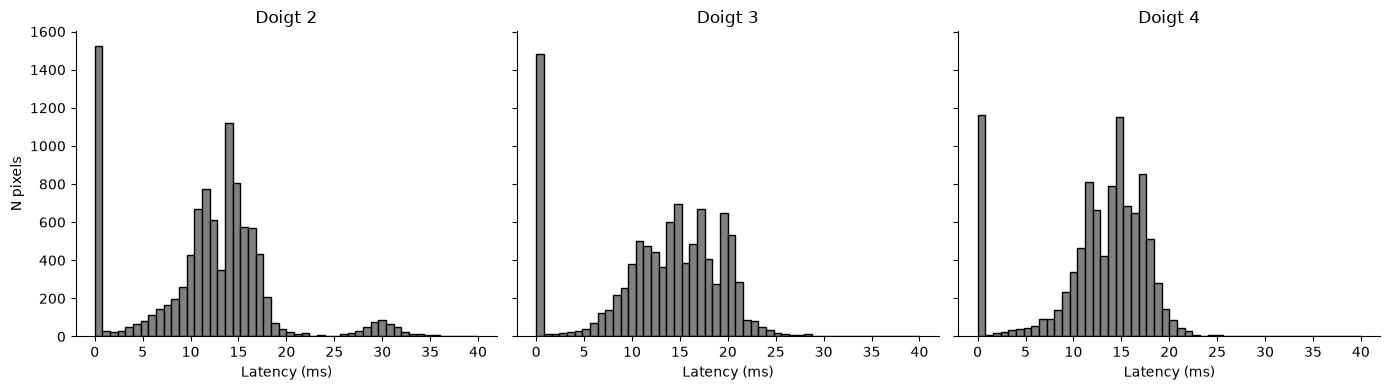

In [66]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

ax[0].hist(cond1_lat.flatten(), bins=50, range=(0, 40), edgecolor='black', color='grey')
ax[1].hist(cond2_lat.flatten(), bins=50, range=(0, 40), edgecolor='black', color='grey')
ax[2].hist(cond3_lat.flatten(), bins=50, range=(0, 40), edgecolor='black', color='grey')

ax[0].set_title('Doigt 2')
ax[1].set_title('Doigt 3')
ax[2].set_title('Doigt 4')

ax[0].set_xlabel('Latency (ms)')
ax[1].set_xlabel('Latency (ms)')
ax[2].set_xlabel('Latency (ms)')

ax[0].set_ylabel('N pixels')

ax[0].spines[['top', 'right']].set_visible(False)
ax[1].spines[['top', 'right']].set_visible(False)
ax[2].spines[['top', 'right']].set_visible(False)

plt.tight_layout()

### 3.3 Extract the contour

/var/folders/hj/zrv88xk141b_66z8wmnrg1d80000gp/T/ipykernel_68926/2218826211.py:11: UserWarning: Adding colorbar to a different Figure <Figure size 1200x500 with 4 Axes> than <Figure size 1200x400 with 4 Axes> which fig.colorbar is called on.
  fig.colorbar(im3, ax=[ax1, ax2, ax3], shrink=0.7)


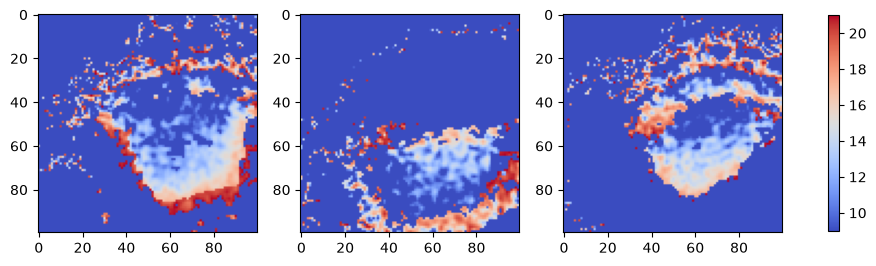

In [67]:
roi1 = np.where((cond1_lat<14) & (cond1_lat>10), cond1_lat, 0)
roi2 = np.where((cond2_lat<14) & (cond2_lat>10), cond2_lat, 0)
roi3 = np.where((cond3_lat<14) & (cond3_lat>10), cond3_lat, 0)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))

ax1.imshow(roi1, cmap='coolwarm', vmin=10, vmax=14)
ax2.imshow(roi2, cmap='coolwarm', vmin=10, vmax=14)
ax3.imshow(roi3, cmap='coolwarm', vmin=10, vmax=14)

fig.colorbar(im3, ax=[ax1, ax2, ax3], shrink=0.7)

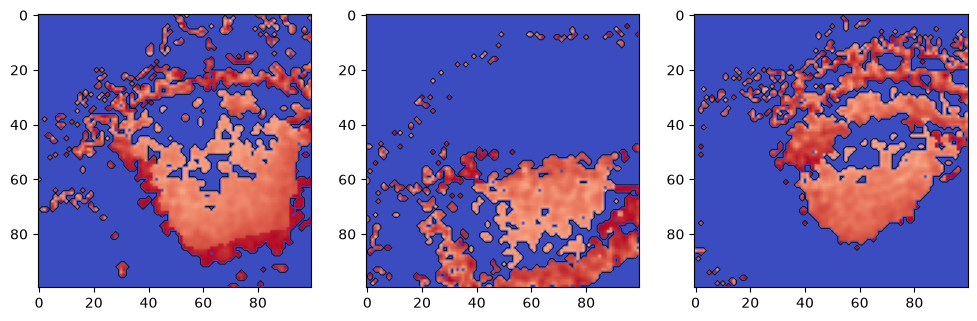

In [68]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(roi1, cmap='coolwarm')
ax[0].contour(roi1, levels=0, linewidths=0.5, colors='black')

ax[1].imshow(roi2, cmap='coolwarm')
ax[1].contour(roi2, levels=0, linewidths=0.5, colors='black')

ax[2].imshow(roi3, cmap='coolwarm')
ax[2].contour(roi3, levels=0, linewidths=0.5, colors='black')

In [69]:
def enclosed_area(s):
    x, y = s[:, 0], s[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

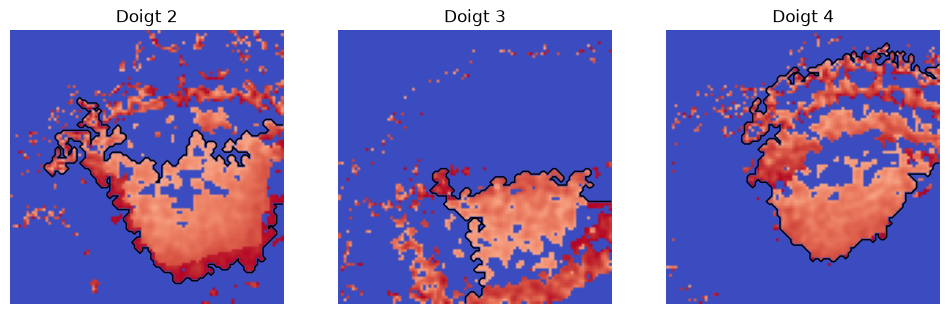

In [70]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(roi1, cmap='coolwarm')
cs1 = ax[0].contour(roi1, levels=0, linewidths=0.5, colors='black')
segs1 = cs1.allsegs[0]
cs1.remove()

ax[1].imshow(roi2, cmap='coolwarm')
cs2 = ax[1].contour(roi2, levels=0, linewidths=0.5, colors='black')
segs2 = cs2.allsegs[0]
cs2.remove()

ax[2].imshow(roi3, cmap='coolwarm')
cs3 = ax[2].contour(roi3, levels=0, linewidths=0.5, colors='black')
segs3 = cs3.allsegs[0]
cs3.remove()

largest1 = max(segs1, key=enclosed_area)
largest2 = max(segs2, key=enclosed_area)
largest3 = max(segs3, key=enclosed_area)

ax[0].plot(largest1[:, 0], largest1[:, 1], color='black', linewidth=1)
ax[1].plot(largest2[:, 0], largest2[:, 1], color='black', linewidth=1)
ax[2].plot(largest3[:, 0], largest3[:, 1], color='black', linewidth=1)

ax[0].set_title('Doigt 2')
ax[1].set_title('Doigt 3')
ax[2].set_title('Doigt 4')

ax[0].set_axis_off()
ax[1].set_axis_off()
ax[2].set_axis_off()

### 3.4 Extract the center

In [71]:
from cv2 import moments

def contour_centroid(c):
    # c: (N, 2) array of (x, y) points, e.g. largest1 from allsegs
    M = moments(c.astype(np.float32).reshape(-1, 1, 2))
    return M["m10"] / M["m00"], M["m01"] / M["m00"]     # (x, y)

center1 = contour_centroid(largest1)
center2 = contour_centroid(largest2)
center3 = contour_centroid(largest3)

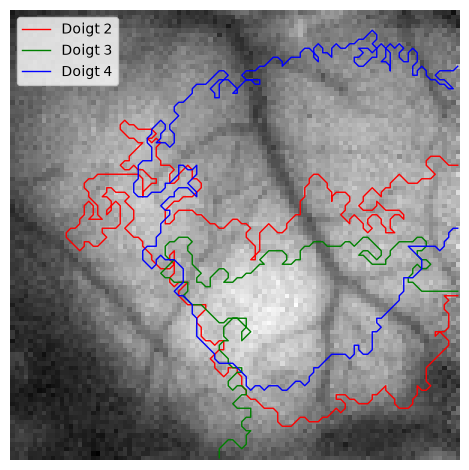

In [72]:
plt.imshow(Cortex)

plt.plot(largest1[:, 0], largest1[:, 1], color='red', linewidth=1, label='Doigt 2')
plt.plot(largest2[:, 0], largest2[:, 1], color='green', linewidth=1, label='Doigt 3')
plt.plot(largest3[:, 0], largest3[:, 1], color='blue', linewidth=1, label='Doigt 4')

plt.axis('off')

plt.legend()
plt.tight_layout()

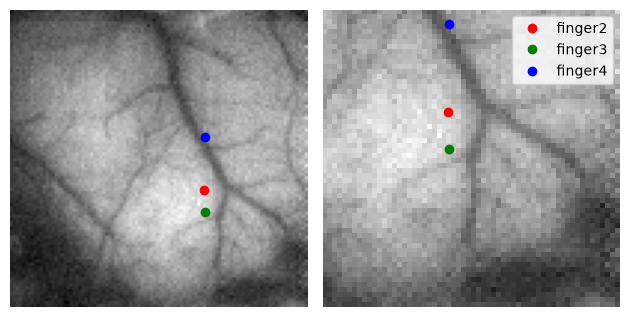

In [73]:
## Zoomed in all together

fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.imshow(Cortex)
ax1.plot(center1[0], center1[1], 'ro', label='finger2')
ax1.plot(center2[0], center2[1], 'go', label='finger3')
ax1.plot(center3[0], center3[1], 'bo', label='finger4')

ax2.imshow(Cortex[40:, 40:])
ax2.plot(center1[0]-40, center1[1]-40, 'ro', label='finger2')
ax2.plot(center2[0]-40, center2[1]-40, 'go', label='finger3')
ax2.plot(center3[0]-40, center3[1]-40, 'bo', label='finger4')

ax1.set_axis_off()
ax2.set_axis_off()
ax3.set_axis_off()

plt.legend()
plt.tight_layout()